## 单斜相ZrO2 不同ansatz 5个轨道

In [1]:
import numpy as np
import mindspore as ms
from mindspore import context, nn, Parameter, Tensor
from mindspore.common.initializer import initializer
import matplotlib.pyplot as plt


from openfermion.chem import MolecularData
from openfermionpyscf import run_pyscf
from mindquantum.core.gates import X
from mindquantum.core.circuit import Circuit
from mindquantum.core.operators import Hamiltonian
from mindquantum.simulator import Simulator
from mindquantum.algorithm.nisq import generate_uccsd
import mindspore as ms

import numpy as np
import mindspore as ms
from mindquantum import *
import matplotlib.pyplot as plt
from mindspore import context, nn, Parameter, Tensor
from mindspore.common.initializer import initializer

In [2]:
from openfermion.chem import MolecularData
from openfermionpyscf import run_pyscf
from mindquantum.core.gates import X
from mindquantum.core.circuit import Circuit
from mindquantum.core.operators import Hamiltonian
from mindquantum.simulator import Simulator
from mindquantum.algorithm.nisq import generate_uccsd
import mindspore as ms

from openfermion.transforms import get_fermion_operator, jordan_wigner
from openfermion.linalg import get_ground_state, get_sparse_operator
import numpy
import scipy
import scipy.linalg

from mindquantum.algorithm.nisq import Transform
from mindquantum.algorithm.nisq import get_qubit_hamiltonian
from mindquantum.algorithm.nisq import uccsd_singlet_generator, uccsd_singlet_get_packed_amplitudes
from mindquantum.core.operators import TimeEvolution, count_qubits
from mindquantum.framework import MQAnsatzOnlyLayer


import itertools
from collections import OrderedDict

import numpy as np

from mindquantum.core.circuit import Circuit, decompose_single_term_time_evolution
from mindquantum.core.operators import FermionOperator, down_index, up_index
from mindquantum.third_party.interaction_operator import InteractionOperator
from mindquantum.utils.type_value_check import _require_package

from mindquantum.algorithm.nisq.chem.transform import Transform
from mindquantum.algorithm.nisq.chem.uccsd import _transform2pauli, _pauli2circuit

import random
import matplotlib.pyplot as plt

ms.set_context(mode=ms.PYNATIVE_MODE, device_target="CPU")

[WARNING] ME(1086847:130091364376576,MainProcess):2025-06-13-09:55:37.881.000 [mindspore/context.py:1335] For 'context.set_context', the parameter 'device_target' will be deprecated and removed in a future version. Please use the api mindspore.set_device() instead.


In [3]:
def _para_uccsd_singlet_generator(mol, threshold=0, n_qubits=0, n_electrons=0):  # pylint: disable=too-many-locals,too-many-statements
    """
    Generate a uccsd quantum circuit.

    Args:
        mol (molecular): A hdf5 molecular file generated by HiQ Fermion.
        threshold (float, optional): A threshold of parameters. If the absolute value of parameter is
            lower than the threshold, than we will not update it in VQE
            algorithm. Default: ``0``.
    """
    if n_qubits == 0:
        n_qubits = mol.n_qubits
        n_electrons = mol.n_electrons
    params = {}
    if n_qubits % 2 != 0:
        raise ValueError('The total number of spin-orbitals should be even.')
    out = []
    out_tmp = []
    n_spatial_orbitals = n_qubits // 2
    n_occupied = int(np.ceil(n_electrons / 2))
    n_virtual = n_spatial_orbitals - n_occupied

    # Unpack amplitudes
    n_single_amplitudes = n_occupied * n_virtual
    # Generate excitations
    spin_index_functions = [up_index, down_index]
    # Generate all spin-conserving single and double excitations derived
    # from one spatial occupied-virtual pair
    for i, (p, q) in enumerate(itertools.product(range(n_virtual), range(n_occupied))):  # pylint: disable=invalid-name
        # Get indices of spatial orbitals
        virtual_spatial = n_occupied + p
        occupied_spatial = q
        virtual_up = virtual_spatial * 2
        occupied_up = occupied_spatial * 2
        virtual_down = virtual_spatial * 2 + 1
        occupied_down = occupied_spatial * 2 + 1
        single_amps = mol.ccsd_single_amps[virtual_up, occupied_up]
        double1_amps = mol.ccsd_double_amps[virtual_up, occupied_up, virtual_down, occupied_down]
        single_amps_name = 'p' + str(i)
        double1_amps_name = 'p' + str(i + n_single_amplitudes)

        for spin in range(2):
            # Get the functions which map a spatial orbital index to a
            # spin orbital index
            this_index = spin_index_functions[spin]
            other_index = spin_index_functions[1 - spin]

            # Get indices of spin orbitals
            virtual_this = this_index(virtual_spatial)
            virtual_other = other_index(virtual_spatial)
            occupied_this = this_index(occupied_spatial)
            occupied_other = other_index(occupied_spatial)

            # Generate single excitations
            if abs(single_amps) > threshold:
                params[single_amps_name] = single_amps
                fermion_ops1 = FermionOperator(((occupied_this, 1), (virtual_this, 0)), 1)
                fermion_ops2 = FermionOperator(((virtual_this, 1), (occupied_this, 0)), 1)
                out.append([fermion_ops1 - fermion_ops2, single_amps_name])

            # Generate double excitation
            if abs(double1_amps) > threshold:
                params[double1_amps_name] = double1_amps
                fermion_ops1 = FermionOperator(
                    ((virtual_this, 1), (occupied_this, 0), (virtual_other, 1), (occupied_other, 0)), 1
                )
                fermion_ops2 = FermionOperator(
                    ((occupied_other, 1), (virtual_other, 0), (occupied_this, 1), (virtual_this, 0)), 1
                )
                out.append([fermion_ops1 - fermion_ops2, double1_amps_name])
    out.extend(out_tmp)
    out_tmp = []
    # Generate all spin-conserving double excitations derived
    # from two spatial occupied-virtual pairs
    for i, ((p, q), (r, s)) in enumerate(  # pylint: disable=invalid-name
        itertools.combinations(itertools.product(range(n_virtual), range(n_occupied)), 2)
    ):

        # Get indices of spatial orbitals
        virtual_spatial_1 = n_occupied + p
        occupied_spatial_1 = q
        virtual_spatial_2 = n_occupied + r
        occupied_spatial_2 = s

        virtual_1_up = virtual_spatial_1 * 2
        occupied_1_up = occupied_spatial_1 * 2
        virtual_2_up = virtual_spatial_2 * 2 + 1
        occupied_2_up = occupied_spatial_2 * 2 + 1

        double2_amps = mol.ccsd_double_amps[virtual_1_up, occupied_1_up, virtual_2_up, occupied_2_up]
        double2_amps_name = 'p' + str(i + 2 * n_single_amplitudes)

        # Generate double excitations
        for (spin_a, spin_b) in itertools.product(range(2), repeat=2):
            # Get the functions which map a spatial orbital index to a
            # spin orbital index
            index_a = spin_index_functions[spin_a]
            index_b = spin_index_functions[spin_b]

            # Get indices of spin orbitals
            virtual_1_a = index_a(virtual_spatial_1)
            occupied_1_a = index_a(occupied_spatial_1)
            virtual_2_b = index_b(virtual_spatial_2)
            occupied_2_b = index_b(occupied_spatial_2)
            if abs(double2_amps) > threshold:
                params[double2_amps_name] = double2_amps
                fermion_ops1 = FermionOperator(
                    ((virtual_1_a, 1), (occupied_1_a, 0), (virtual_2_b, 1), (occupied_2_b, 0)), 1
                )
                fermion_ops2 = FermionOperator(
                    ((occupied_2_b, 1), (virtual_2_b, 0), (occupied_1_a, 1), (virtual_1_a, 0)), 1
                )
                out.append([fermion_ops1 - fermion_ops2, double2_amps_name])
    return out, params

def generate_uccsd(molecular, threshold=-1, active_space_start=None, active_space_stop=None):
    """
    Generate a uccsd quantum circuit based on a molecular data generated by Openfermion.

    Args:
        molecular (Union[str, MolecularData]): the name of the molecular data file,
            or openfermion MolecularData.
        threshold (float): the threshold to filter out the uccsd amplitude. We only keep the
            excitation operator with absolute value of amplitude greater than `threshold`, so
            that if `threshold=0`, we only keep excitation operator with non zero amplitude. Default: ``0``.

    Returns:
        - **uccsd_circuit** (Circuit), the ansatz circuit generated by uccsd method.
        - **initial_amplitudes** (numpy.ndarray), the initial parameter values of uccsd circuit.
        - **parameters_name** (list[str]), the name of initial parameters.
        - **qubit_hamiltonian** (QubitOperator), the hamiltonian of the molecule.
        - **n_qubits** (int), the number of qubits in simulation.
        - **n_electrons** (int), the number of electrons of the molecule.
    """
    try:
        # pylint: disable=import-outside-toplevel
        from openfermion.chem import MolecularData
    except (ImportError, AttributeError):
        _require_package("openfermion", "1.5.0")
    if isinstance(molecular, str):
        mol = MolecularData(filename=molecular)
        mol.load()
    else:
        mol = molecular
    fermion_ansatz, parameters = _para_uccsd_singlet_generator(mol, threshold, n_qubits=2*(active_space_stop-active_space_start), n_electrons=mol.n_electrons-2*active_space_start)
    pauli_ansatz = _transform2pauli(fermion_ansatz)
    uccsd_circuit = _pauli2circuit(pauli_ansatz)
    ham_of = mol.get_molecular_hamiltonian(list(range(active_space_start)), active_indices=range(active_space_start, active_space_stop))
    inter_ops = InteractionOperator(*ham_of.n_body_tensors.values())
    ham_hiq = FermionOperator(inter_ops)
    qubit_hamiltonian = Transform(ham_hiq).jordan_wigner()
    qubit_hamiltonian = qubit_hamiltonian.compress()

    parameters_name = list(parameters.keys())
    initial_amplitudes = [parameters[i] for i in parameters_name]
    return uccsd_circuit, initial_amplitudes, parameters_name, qubit_hamiltonian, 2*(active_space_stop-active_space_start), mol.n_electrons-2*active_space_start

In [4]:
def get_mol(phase=1):
    # 根据输入phase选择不同的晶体结构
    if phase == 1:
        # ① 单斜相ZrO2
        a = 5.15  # Å
        b = 5.23  # Å
        c = 5.33  # Å
        beta = 99.44 * np.pi / 180  # 弧度
        # 晶胞向量
        a_vec = np.array([a, 0, 0])
        b_vec = np.array([0, b, 0])
        c_vec = np.array([c * np.cos(beta), 0, c * np.sin(beta)])
        # 原子分数坐标和元素
        atoms = [
            ('Zr', [0.276309, 0.042147, 0.209598]),
            ('O',  [0.930791, 0.833712, 0.156172]),
            ('O',  [0.449303, 0.742580, 0.978604])
        ]
        description = "Monoclinic ZrO2"
    elif phase == 2:
        # ② 四方相ZrO2
        a = b = 3.60  # Å
        c = 5.23      # Å
        a_vec = np.array([a, 0, 0])
        b_vec = np.array([0, b, 0])
        c_vec = np.array([0, 0, c])
        atoms = [
            ('Zr', [0, 0, 0]),
            ('O',  [0, 0.5, 0.301775])
        ]
        description = "Tetragonal ZrO2"
    elif phase == 3:
        # ③ 六方相ZrO
        a = 5.31  # Å
        c = 3.2   # Å
        a_vec = np.array([a, 0, 0])
        b_vec = np.array([-a/2, a*np.sqrt(3)/2, 0])
        c_vec = np.array([0, 0, c])
        atoms = [
            ('Zr', [0, 0, 0]),
            ('O',  [1/3, 2/3, 0.25])
        ]
        description = "Hexagonal ZrO"
    else:
        raise ValueError("Invalid phase. Choose 1, 2, or 3.")

    # 将分数坐标转换为笛卡尔坐标
    geometry = []
    for element, frac_coords in atoms:
        # 分数坐标转换为笛卡尔坐标
        cart_coords = (
            frac_coords[0] * a_vec +
            frac_coords[1] * b_vec +
            frac_coords[2] * c_vec
        )
        geometry.append([element, list(cart_coords)])
    print(geometry)

    # 设置基组和自旋多重性
    basis = 'gth-dzvp-molopt-sr'
    multiplicity = 1  # 假设为闭壳层单重态

    # 创建分子对象
    molecule = MolecularData(
        geometry,
        basis,
        multiplicity,
        description=description
    )

    # molecule = run_pyscf(
    #     molecule,
    #     run_scf=1,
    #     run_ccsd=1,
    #     #run_fci=1
    # )

    # 显式指定文件名
    #molecule.filename = "./test_h2.hdf5"
    # molecule.save()
    # molecule_file = molecule.filename
    # print(molecule_file.split('/')[-1])

    # 运行或加载计算
    try:
        molecule.load()
    except:
        molecule = run_pyscf(
            molecule,
            run_scf=1,
            run_ccsd=1,
        )
        molecule.save()
        molecule.load()
        molecule_file = molecule.filename
        print(molecule_file.split('/')[-1])

    # 打印能量信息
    print(f'{description} - Hartree-Fock energy: {molecule.hf_energy} Hartree.')
    print(f'{description} - CCSD energy: {molecule.ccsd_energy} Hartree.')
   # print(f'{description} - FCI energy: {molecule.fic_energy} Hartree.')

    
    return molecule

## 单斜相ZrO2

In [5]:
ZrO2d=get_mol(1)

[['Zr', [1.2397611467218508, 0.22042881, 1.102028681533527]], ['O', [4.657048362037544, 4.36031376, 0.8211243583071115]], ['O', [1.4584165528787967, 3.8836934000000003, 5.145324267709785]]]
Monoclinic ZrO2 - Hartree-Fock energy: -608.1196082141597 Hartree.
Monoclinic ZrO2 - CCSD energy: -608.3663660904948 Hartree.


## 5轨道 初始UCCSD ansatz

In [6]:
ansatz_circuit, \
init_amplitudes, \
ansatz_parameter_names, \
hamiltonian_QubitOp, \
n_qubits, n_electrons = generate_uccsd(ZrO2d, threshold=-1,active_space_start=27, active_space_stop=32)

In [7]:
## 总结线路
hartreefock_wfn_circuit = Circuit([X.on(i) for i in range(n_electrons)])
total_circuit = hartreefock_wfn_circuit + ansatz_circuit
total_circuit.summary()
print("Number of parameters: %d" % (len(ansatz_parameter_names)))

                          Circuit Summary                           
╭──────────────────────┬───────────────────────────────────────────╮
│ Info                 │ value                                     │
├──────────────────────┼───────────────────────────────────────────┤
│ Number of qubit      │ 10                                        │
├──────────────────────┼───────────────────────────────────────────┤
│ Total number of gate │ 2610                                      │
│ Barrier              │ 576                                       │
│ Noise Channel        │ 0                                         │
│ Measurement          │ 0                                         │
├──────────────────────┼───────────────────────────────────────────┤
│ Parameter gate       │ 144                                       │
│ 14 ansatz parameters │ p0, p4, p1, p5, p2, p6, p3, p7, p8, p9... │
╰──────────────────────┴───────────────────────────────────────────╯

Number of parameters: 14


In [8]:
ham = Hamiltonian(hamiltonian_QubitOp)      # 生成哈密顿量
#init_state_circ = UN(H, g_6.nodes)         # 生成均匀叠加态，即对所有量子比特作用H门
ansatz = ansatz_circuit   # 生成拟设线路
circ = hartreefock_wfn_circuit + ansatz_circuit.as_encoder()       # 将初始化线路与拟设线路组合成总的线路

In [25]:
sim = Simulator('mqvector', circ.n_qubits) # 创建模拟器
grad_ops = sim.get_expectation_with_grad(ham, circ)

In [18]:
# 采用一个 LSTM 作为对量子线路参数的经典优化器
# LSTM 输入为量子线路旧的参数，输出作为量子线路新的参数。
class TrainableLSTM(nn.Cell):
    def __init__(self):
        super(TrainableLSTM, self).__init__()
        self.lstm = nn.LSTM(input_size=len(circ.params_name),
                                            hidden_size=len(circ.params_name),
                                            num_layers=1,
                                            has_bias=True,
                                            batch_first=False,
                                            bidirectional=False)
        self.hidden_size = self.lstm.hidden_size
        self.batch_size = 1
        self.num_layers = 1
        self.hx = (Parameter(initializer( 'normal', shape=[self.num_layers, self.batch_size, self.hidden_size], dtype=ms.float32), name='h'),
                         Parameter(initializer('normal', shape=[self.num_layers, self.batch_size, self.hidden_size], dtype=ms.float32), name='c'))

    def construct(self, x):
        _, (x, _) = self.lstm(x, self.hx)
        return x


In [19]:
# LSTM 层的损失函数为量子线路最终的期望值。
class All_Net(nn.Cell):
    def __init__(self, grad_ops, init_paras):
        super(All_Net, self).__init__()
        self.lstm = TrainableLSTM()
        self.qnn_ops = MQEncoderOnlyOps(grad_ops) # 量子线路的参数不直接参与训练
        self.init_paras = init_paras
        self.squeeze = ms.ops.Squeeze(0)

    def construct(self):  # x 为量子线路旧的网络参数， out 为量子线路新的参数
        self.init_paras = self.lstm(self.init_paras)
        x = self.squeeze(self.init_paras)
        out = self.qnn_ops(x)
        return out

In [26]:

paras = Tensor(np.random.random([1, 1, len(circ.params_name)]).astype(np.float32))  # 量子线路初始参数
all_net = All_Net(grad_ops, paras)
opt = nn.Adam(all_net.trainable_params(),  learning_rate=0.1)  # 对 LSTM 层的参数，采用 Adam 进行优化
train_net = nn.TrainOneStepCell(all_net, opt)
train_net.set_train()

TrainOneStepCell<
  (network): All_Net<
    (lstm): TrainableLSTM<
      (lstm): LSTM<
        (rnn): _DynamicLSTMCPUGPU<>
        (dropout_op): Dropout<p=0.0>
        >
      >
    (qnn_ops): MQEncoderOnlyOps<10 qubits mqvector VQA Operator>
    >
  (optimizer): Adam<>
  (grad_reducer): Identity<>
  >

In [27]:
# 训练过程
energy_data = []
steps = 100
for step in range(steps):
    energy = train_net()
    energy_data.append(energy.asnumpy()[0, 0])
    if step % 10 == 0:
        print(f"Step {step}: Energy = {energy[0, 0]}")

Step 0: Energy = -607.2968
Step 10: Energy = -608.10583
Step 20: Energy = -608.1151
Step 30: Energy = -608.11847
Step 40: Energy = -608.1191
Step 50: Energy = -608.1193
Step 60: Energy = -608.1195
Step 70: Energy = -608.1195
Step 80: Energy = -608.11957
Step 90: Energy = -608.11957


/tmp/ipykernel_1085588/898229535.py:5: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


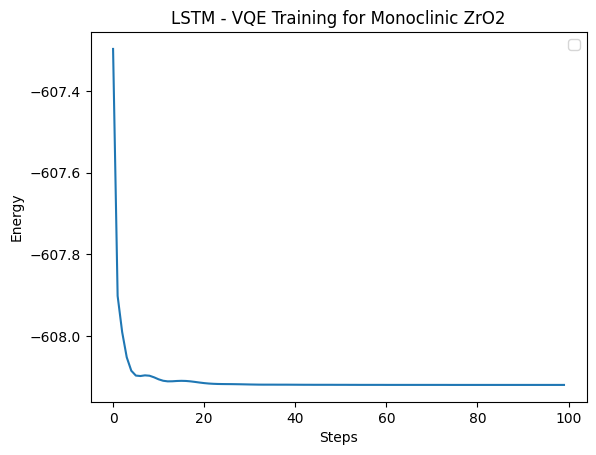

Estimated ground state energy of Monoclinic ZrO2: -608.1195678710938


In [28]:
# 绘制能量变化曲线
plt.figure()
plt.plot(energy_data)
plt.title('LSTM - VQE Training for Monoclinic ZrO2', fontsize=12)
plt.legend()
plt.xlabel('Steps', fontsize=10)
plt.ylabel('Energy', fontsize=10)
#plt.savefig('lstm_vqe_lih_energy.png')
plt.show()

print(f"Estimated ground state energy of Monoclinic ZrO2: {energy_data[-1]}")

In [16]:
 -608.1197509765625

-608.1197509765625

In [29]:
print('L1_UCCSD=',energy_data)

L1_UCCSD= [-607.2968, -607.90173, -607.9904, -608.0519, -608.0848, -608.0967, -608.0978, -608.0961, -608.09705, -608.10095, -608.10583, -608.1094, -608.11084, -608.11066, -608.1099, -608.10956, -608.10986, -608.11084, -608.11224, -608.1138, -608.1151, -608.11615, -608.1168, -608.11725, -608.11743, -608.11755, -608.1176, -608.1178, -608.118, -608.1182, -608.11847, -608.11865, -608.11884, -608.1189, -608.1189, -608.1189, -608.11896, -608.11896, -608.11896, -608.119, -608.1191, -608.11914, -608.1192, -608.1192, -608.11926, -608.11926, -608.11926, -608.11926, -608.11926, -608.1193, -608.1193, -608.1193, -608.1194, -608.1194, -608.11945, -608.11945, -608.11945, -608.11945, -608.11945, -608.11945, -608.1195, -608.1195, -608.1195, -608.1195, -608.1195, -608.1195, -608.1195, -608.1195, -608.1195, -608.1195, -608.1195, -608.1195, -608.1195, -608.1195, -608.11957, -608.11957, -608.11957, -608.11957, -608.11957, -608.11957, -608.11957, -608.11957, -608.11957, -608.11957, -608.11957, -608.11957, -

## HardwareEfficientAnsatz

In [30]:
n_qubits

10

In [179]:
from mindquantum.algorithm.nisq import HardwareEfficientAnsatz 
from mindquantum.core.gates import RY,RZ
ansatz_circuit2 = HardwareEfficientAnsatz(n_qubits, single_rot_gate_seq=[RY, RZ], entangle_gate=Z, depth=1).circuit     # 通过HardwareEfficientAnsatz搭建Ansatz

In [180]:
ham = Hamiltonian(hamiltonian_QubitOp)      # 生成哈密顿量
#init_state_circ = UN(H, g_6.nodes)         # 生成均匀叠加态，即对所有量子比特作用H门
ansatz = ansatz_circuit2   # 生成拟设线路
circ = hartreefock_wfn_circuit + ansatz_circuit2.as_encoder()       # 将初始化线路与拟设线路组合成总的线路

In [181]:
circ.summary()

                                       Circuit Summary                                       
╭───────────────────────┬───────────────────────────────────────────────────────────────────╮
│ Info                  │ value                                                             │
├───────────────────────┼───────────────────────────────────────────────────────────────────┤
│ Number of qubit       │ 10                                                                │
├───────────────────────┼───────────────────────────────────────────────────────────────────┤
│ Total number of gate  │ 51                                                                │
│ Barrier               │ 0                                                                 │
│ Noise Channel         │ 0                                                                 │
│ Measurement           │ 0                                                                 │
├───────────────────────┼───────────────────────────────────────────────────────────────────┤
│ Parameter gate        │ 40                                                                │
│ 40 encoder parameters │ d0_n0_0, d0_n0_1, d0_n1_0, d0_n1_1, d0_n2_0, d0_n2_1, d0_n3_0,    │
│                       │ d0_n3_1, d0_n4_0, d0_n4_1...                                      │
╰───────────────────────┴───────────────────────────────────────────────────────────────────╯

In [182]:
sim = Simulator('mqvector', circ.n_qubits)
grad_ops = sim.get_expectation_with_grad(Hamiltonian(hamiltonian_QubitOp), circ)

In [183]:
 len(circ.params_name)

40

In [184]:
paras = Tensor(np.random.random([1, 1, len(circ.params_name)]).astype(np.float32))  # 量子线路初始参数
all_net = All_Net(grad_ops, paras)
opt = nn.Adam(all_net.trainable_params(),  learning_rate=0.1)  # 对 LSTM 层的参数，采用 Adam 进行优化
train_net = nn.TrainOneStepCell(all_net, opt)
train_net.set_train()

TrainOneStepCell<
  (network): All_Net<
    (lstm): TrainableLSTM<
      (lstm): LSTM<
        (rnn): _DynamicLSTMCPUGPU<>
        (dropout_op): Dropout<p=0.0>
        >
      >
    (qnn_ops): MQEncoderOnlyOps<10 qubits mqvector VQA Operator>
    >
  (optimizer): Adam<>
  (grad_reducer): Identity<>
  >

In [185]:
# 训练过程
energy_data = []
steps = 100
for step in range(steps):
    energy = train_net()
    energy_data.append(energy.asnumpy()[0, 0])
    if step % 10 == 0:
        print(f"Step {step}: Energy = {energy[0, 0]}")

Step 0: Energy = -608.12573
Step 10: Energy = -608.81866
Step 20: Energy = -608.8284
Step 30: Energy = -608.82837
Step 40: Energy = -608.82837
Step 50: Energy = -608.8284
Step 60: Energy = -608.8289
Step 70: Energy = -608.82886
Step 80: Energy = -608.8289
Step 90: Energy = -608.8289


/tmp/ipykernel_1086847/898229535.py:5: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


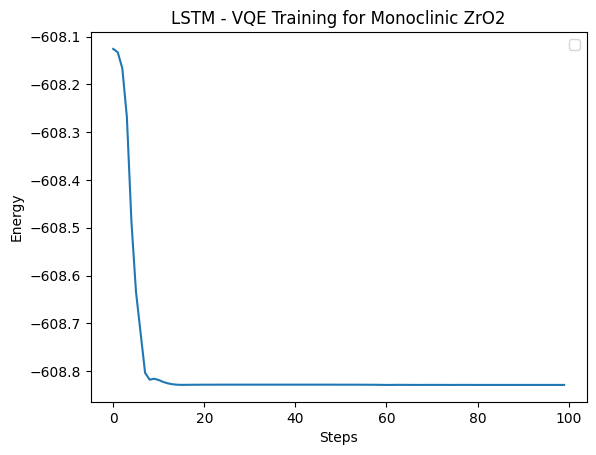

Estimated ground state energy of Monoclinic ZrO2: -608.8289184570312


In [186]:
# 绘制能量变化曲线
plt.figure()
plt.plot(energy_data)
plt.title('LSTM - VQE Training for Monoclinic ZrO2', fontsize=12)
plt.legend()
plt.xlabel('Steps', fontsize=10)
plt.ylabel('Energy', fontsize=10)
#plt.savefig('lstm_vqe_lih_energy.png')
plt.show()

print(f"Estimated ground state energy of Monoclinic ZrO2: {energy_data[-1]}")

In [93]:
-608.8303833007812

-608.8303833007812

In [153]:
print('L1_HEF=',energy_data)

L1_HEF= [-607.16125, -607.1692, -607.19446, -607.2716, -607.4217, -607.5757, -607.65906, -607.6894, -607.701, -607.7082, -607.71326, -607.7184, -607.7223, -607.72296, -607.723, -607.723, -607.72314, -607.7232, -607.72327, -607.7233, -607.7234, -607.72345, -607.72345, -607.72345, -607.7235, -607.7236, -607.72363, -607.72375, -607.7238, -607.72363, -607.7237, -607.7238, -607.7238, -607.72375, -607.72375, -607.72375, -607.72375, -607.7238, -607.7238, -607.7239, -607.7239, -607.7238, -607.7239, -607.72394, -607.724, -607.72406, -607.72406, -607.724, -607.724, -607.72406, -607.7241, -607.7241, -607.72406, -607.72406, -607.72406, -607.72406, -607.72406, -607.7241, -607.7241, -607.7241, -607.7241, -607.7241, -607.7241, -607.7241, -607.7241, -607.7241, -607.7241, -607.7241, -607.7241, -607.7241, -607.7241, -607.7241, -607.7241, -607.7241, -607.7241, -607.7241, -607.7241, -607.7241, -607.7241, -607.7241, -607.7241, -607.7241, -607.7241, -607.7241, -607.7241, -607.7241, -607.7241, -607.7241, -60

In [187]:
print('L1_HEF_Z=',energy_data)

L1_HEF_Z= [-608.12573, -608.13275, -608.1662, -608.26807, -608.4867, -608.63367, -608.7187, -608.80347, -608.818, -608.816, -608.81866, -608.82275, -608.8257, -608.82745, -608.8285, -608.8288, -608.82874, -608.8286, -608.82855, -608.8285, -608.8284, -608.8284, -608.8284, -608.82837, -608.82837, -608.82837, -608.82837, -608.82837, -608.82837, -608.82837, -608.82837, -608.82837, -608.82837, -608.82837, -608.82837, -608.82837, -608.82837, -608.82837, -608.82837, -608.82837, -608.82837, -608.82837, -608.82837, -608.82837, -608.82837, -608.82837, -608.82837, -608.82837, -608.82837, -608.8284, -608.8284, -608.8284, -608.8284, -608.8284, -608.8285, -608.8285, -608.82855, -608.8286, -608.8287, -608.8288, -608.8289, -608.8289, -608.8288, -608.82874, -608.8288, -608.82886, -608.8289, -608.8289, -608.82886, -608.82886, -608.82886, -608.82886, -608.82886, -608.8289, -608.8289, -608.8289, -608.82886, -608.82886, -608.82886, -608.8289, -608.8289, -608.8289, -608.8289, -608.8289, -608.8289, -608.8289

##  QubitUCCAnsatz

In [85]:
from mindquantum.algorithm.nisq import QubitUCCAnsatz
ansatz_circuit3 = QubitUCCAnsatz(10, 4, trotter_step=2).circuit 

In [86]:
ham = Hamiltonian(hamiltonian_QubitOp)      # 生成哈密顿量
#init_state_circ = UN(H, g_6.nodes)         # 生成均匀叠加态，即对所有量子比特作用H门
#ansatz = ansatz_circuit3   # 生成拟设线路
circ = hartreefock_wfn_circuit + ansatz_circuit3.as_encoder()       # 将初始化线路与拟设线路组合成总的线路

In [87]:
circ.summary()

                                       Circuit Summary                                       
╭────────────────────────┬──────────────────────────────────────────────────────────────────╮
│ Info                   │ value                                                            │
├────────────────────────┼──────────────────────────────────────────────────────────────────┤
│ Number of qubit        │ 10                                                               │
├────────────────────────┼──────────────────────────────────────────────────────────────────┤
│ Total number of gate   │ 2126                                                             │
│ Barrier                │ 0                                                                │
│ Noise Channel          │ 0                                                                │
│ Measurement            │ 0                                                                │
├────────────────────────┼──────────────────────────────────────────────────────────────────┤
│ Parameter gate         │ 228                                                              │
│ 228 encoder parameters │ t_0_q_s_0, t_0_q_s_1, t_0_q_s_2, t_0_q_s_3, t_0_q_s_4,           │
│                        │ t_0_q_s_5, t_0_q_s_6, t_0_q_s_7, t_0_q_s_8, t_0_q_s_9...         │
╰────────────────────────┴──────────────────────────────────────────────────────────────────╯

In [88]:
sim = Simulator('mqvector', circ.n_qubits)
grad_ops = sim.get_expectation_with_grad(Hamiltonian(hamiltonian_QubitOp), circ)

In [90]:
paras = Tensor(np.random.random([1, 1, len(circ.params_name)]).astype(np.float32))  # 量子线路初始参数
all_net = All_Net(grad_ops, paras)
opt = nn.Adam(all_net.trainable_params(),  learning_rate=0.1)  # 对 LSTM 层的参数，采用 Adam 进行优化
train_net = nn.TrainOneStepCell(all_net, opt)
train_net.set_train()

TrainOneStepCell<
  (network): All_Net<
    (lstm): TrainableLSTM<
      (lstm): LSTM<
        (rnn): _DynamicLSTMCPUGPU<>
        (dropout_op): Dropout<p=0.0>
        >
      >
    (qnn_ops): MQEncoderOnlyOps<10 qubits mqvector VQA Operator>
    >
  (optimizer): Adam<>
  (grad_reducer): Identity<>
  >

In [91]:
# 训练过程
energy_data = []
steps = 100
for step in range(steps):
    energy = train_net()
    energy_data.append(energy.asnumpy()[0, 0])
    if step % 10 == 0:
        print(f"Step {step}: Energy = {energy[0, 0]}")

Step 0: Energy = -607.9197
Step 10: Energy = -608.11957
Step 20: Energy = -608.1196
Step 30: Energy = -608.1196
Step 40: Energy = -608.1196
Step 50: Energy = -608.1196
Step 60: Energy = -608.1196
Step 70: Energy = -608.1196
Step 80: Energy = -608.1196
Step 90: Energy = -608.1196


/tmp/ipykernel_1086847/898229535.py:5: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


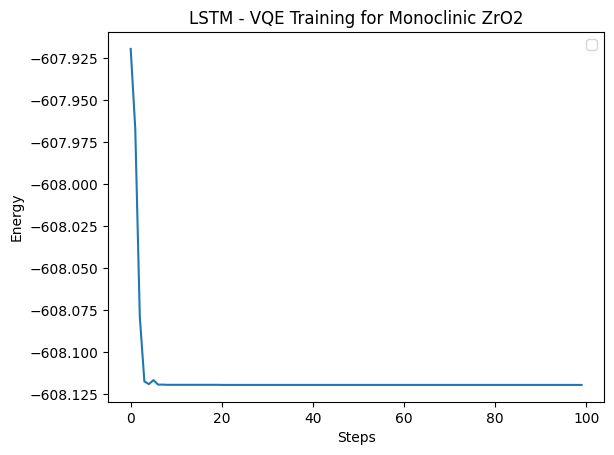

Estimated ground state energy of Monoclinic ZrO2: -608.11962890625


In [92]:
# 绘制能量变化曲线
plt.figure()
plt.plot(energy_data)
plt.title('LSTM - VQE Training for Monoclinic ZrO2', fontsize=12)
plt.legend()
plt.xlabel('Steps', fontsize=10)
plt.ylabel('Energy', fontsize=10)
#plt.savefig('lstm_vqe_lih_energy.png')
plt.show()

print(f"Estimated ground state energy of Monoclinic ZrO2: {energy_data[-1]}")

In [94]:
-608.11962890625

-608.11962890625

In [95]:
print('L1_qUCC=',energy_data)

L1_qUCC= [-607.9197, -607.96704, -608.07904, -608.11755, -608.11914, -608.11676, -608.11945, -608.11945, -608.11957, -608.11957, -608.11957, -608.11957, -608.11957, -608.11957, -608.11957, -608.11957, -608.11957, -608.11957, -608.11957, -608.11957, -608.1196, -608.1196, -608.1196, -608.1196, -608.1196, -608.1196, -608.1196, -608.1196, -608.1196, -608.1196, -608.1196, -608.1196, -608.1196, -608.1196, -608.1196, -608.1196, -608.1196, -608.1196, -608.1196, -608.1196, -608.1196, -608.1196, -608.1196, -608.1196, -608.1196, -608.1196, -608.1196, -608.1196, -608.1196, -608.1196, -608.1196, -608.1196, -608.1196, -608.1196, -608.1196, -608.1196, -608.1196, -608.1196, -608.1196, -608.1196, -608.1196, -608.1196, -608.1196, -608.1196, -608.1196, -608.1196, -608.1196, -608.1196, -608.1196, -608.1196, -608.1196, -608.1196, -608.1196, -608.1196, -608.1196, -608.1196, -608.1196, -608.1196, -608.1196, -608.1196, -608.1196, -608.1196, -608.1196, -608.1196, -608.1196, -608.1196, -608.1196, -608.1196, -60

## StronglyEntangling

In [188]:
from mindquantum.algorithm.nisq import StronglyEntangling
ansatz_circuit4 = StronglyEntangling(10,2, Z).circuit 

In [189]:
ham = Hamiltonian(hamiltonian_QubitOp)      # 生成哈密顿量
#init_state_circ = UN(H, g_6.nodes)         # 生成均匀叠加态，即对所有量子比特作用H门
#ansatz = ansatz_circuit3   # 生成拟设线路
circ = hartreefock_wfn_circuit + ansatz_circuit4.as_encoder()       # 将初始化线路与拟设线路组合成总的线路

In [190]:
circ.summary()

                                       Circuit Summary                                       
╭───────────────────────┬───────────────────────────────────────────────────────────────────╮
│ Info                  │ value                                                             │
├───────────────────────┼───────────────────────────────────────────────────────────────────┤
│ Number of qubit       │ 10                                                                │
├───────────────────────┼───────────────────────────────────────────────────────────────────┤
│ Total number of gate  │ 42                                                                │
│ Barrier               │ 0                                                                 │
│ Noise Channel         │ 0                                                                 │
│ Measurement           │ 0                                                                 │
├───────────────────────┼───────────────────────────────────────────────────────────────────┤
│ Parameter gate        │ 20                                                                │
│ 60 encoder parameters │ l0_a0, l0_b0, l0_c0, l0_a1, l0_b1, l0_c1, l0_a2, l0_b2, l0_c2,    │
│                       │ l0_a3...                                                          │
╰───────────────────────┴───────────────────────────────────────────────────────────────────╯

In [191]:
sim = Simulator('mqvector', circ.n_qubits)
grad_ops = sim.get_expectation_with_grad(Hamiltonian(hamiltonian_QubitOp), circ)

In [192]:
paras = Tensor(np.random.random([1, 1, len(circ.params_name)]).astype(np.float32))  # 量子线路初始参数
all_net = All_Net(grad_ops, paras)
opt = nn.Adam(all_net.trainable_params(),  learning_rate=0.1)  # 对 LSTM 层的参数，采用 Adam 进行优化
train_net = nn.TrainOneStepCell(all_net, opt)
train_net.set_train()

TrainOneStepCell<
  (network): All_Net<
    (lstm): TrainableLSTM<
      (lstm): LSTM<
        (rnn): _DynamicLSTMCPUGPU<>
        (dropout_op): Dropout<p=0.0>
        >
      >
    (qnn_ops): MQEncoderOnlyOps<10 qubits mqvector VQA Operator>
    >
  (optimizer): Adam<>
  (grad_reducer): Identity<>
  >

In [193]:
# 训练过程
energy_data = []
steps = 100
for step in range(steps):
    energy = train_net()
    energy_data.append(energy.asnumpy()[0, 0])
    if step % 10 == 0:
        print(f"Step {step}: Energy = {energy[0, 0]}")

Step 0: Energy = -608.1157
Step 10: Energy = -608.81464
Step 20: Energy = -608.82886
Step 30: Energy = -608.8287
Step 40: Energy = -608.8287
Step 50: Energy = -608.8287
Step 60: Energy = -608.82874
Step 70: Energy = -608.82874
Step 80: Energy = -608.82874
Step 90: Energy = -608.82935


/tmp/ipykernel_1086847/898229535.py:5: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


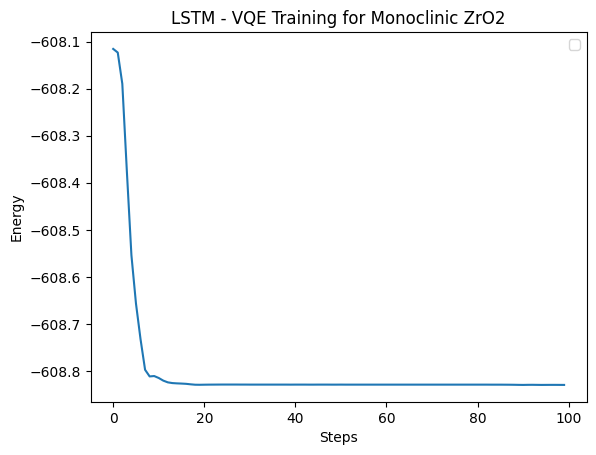

Estimated ground state energy of Monoclinic ZrO2: -608.829345703125


In [194]:
# 绘制能量变化曲线
plt.figure()
plt.plot(energy_data)
plt.title('LSTM - VQE Training for Monoclinic ZrO2', fontsize=12)
plt.legend()
plt.xlabel('Steps', fontsize=10)
plt.ylabel('Energy', fontsize=10)
#plt.savefig('lstm_vqe_lih_energy.png')
plt.show()

print(f"Estimated ground state energy of Monoclinic ZrO2: {energy_data[-1]}")

In [107]:
-607.5455322265625

-607.5455322265625

In [178]:
print('L1_SE=',energy_data)

L1_SE= [-606.46265, -606.4491, -606.5097, -606.694, -607.0541, -607.34143, -607.46985, -607.50507, -607.52045, -607.526, -607.5336, -607.53845, -607.53656, -607.5383, -607.54333, -607.5441, -607.54474, -607.5436, -607.543, -607.54425, -607.5447, -607.54486, -607.54626, -607.54663, -607.5462, -607.54694, -607.54706, -607.5468, -607.5468, -607.54694, -607.5473, -607.5473, -607.5472, -607.5474, -607.5475, -607.5474, -607.5474, -607.5475, -607.54755, -607.54755, -607.5475, -607.5476, -607.5476, -607.5476, -607.5476, -607.5476, -607.54767, -607.5476, -607.54767, -607.54767, -607.54767, -607.54767, -607.54767, -607.54767, -607.54767, -607.54767, -607.54767, -607.54767, -607.54767, -607.54767, -607.54767, -607.54767, -607.54767, -607.54767, -607.54767, -607.54767, -607.54767, -607.54767, -607.54767, -607.54767, -607.54767, -607.54767, -607.54767, -607.54767, -607.54767, -607.54767, -607.5477, -607.5477, -607.5477, -607.5477, -607.5477, -607.5477, -607.5477, -607.5477, -607.5477, -607.5477, -6

In [195]:
print('L1_SE_Z=',energy_data)

L1_SE_Z= [-608.1157, -608.1234, -608.18976, -608.3757, -608.55383, -608.6565, -608.7321, -608.7972, -608.8113, -608.8105, -608.81464, -608.82025, -608.8239, -608.82544, -608.82605, -608.8265, -608.827, -608.82806, -608.8289, -608.82904, -608.82886, -608.82874, -608.8287, -608.8286, -608.82855, -608.82855, -608.82855, -608.82855, -608.8286, -608.8286, -608.8287, -608.8287, -608.8287, -608.8287, -608.8287, -608.8287, -608.8287, -608.8287, -608.8287, -608.82874, -608.8287, -608.8287, -608.8287, -608.82874, -608.82874, -608.8287, -608.8287, -608.8287, -608.82874, -608.82874, -608.8287, -608.82874, -608.82874, -608.82874, -608.82874, -608.82874, -608.82874, -608.82874, -608.82874, -608.82874, -608.82874, -608.82874, -608.82874, -608.82874, -608.82874, -608.82874, -608.82874, -608.82874, -608.82874, -608.82874, -608.82874, -608.82874, -608.82874, -608.82874, -608.82874, -608.82874, -608.82874, -608.82874, -608.82874, -608.82874, -608.82874, -608.82874, -608.82874, -608.8288, -608.8288, -608.

## HEF Z作为双比特门